# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [144]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans
# you will need to import more libraries as needed

In [145]:
# my plot style: greens on a white grid
sns.set_theme(style='whitegrid', palette='Greens_d')

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [146]:
customer_data = pd.read_csv('shopping-data.csv')

In [147]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [148]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

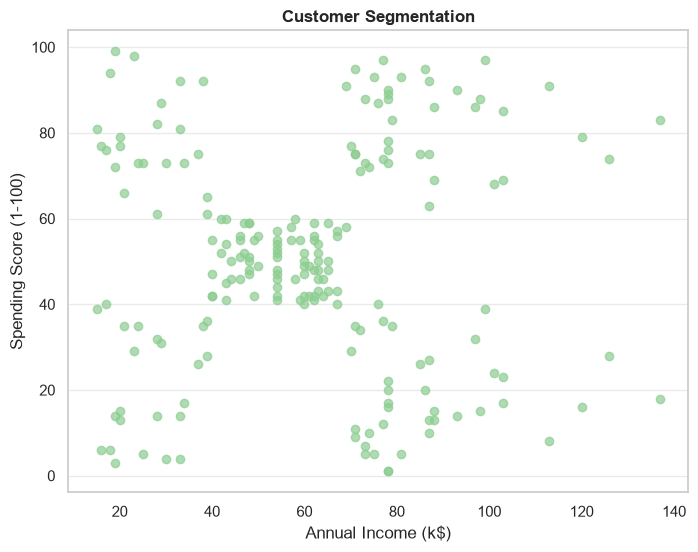

In [149]:
plt.figure(figsize=(8, 6))
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'], alpha=0.7)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation')
plt.show()

By the way, we can clearly see 5 groups 

#### 3. Normalize the data

In [150]:
# scale income and spending score
scaler = StandardScaler()
shop_scaled = scaler.fit_transform(customer_data[['Annual Income (k$)', 'Spending Score (1-100)']])

# check: mean = 0, std =1
print(shop_scaled.mean(axis=0).round(2), shop_scaled.std(axis=0).round(2))


[-0. -0.] [1. 1.]


#### 4. Use Elbow method to decide number of clusters

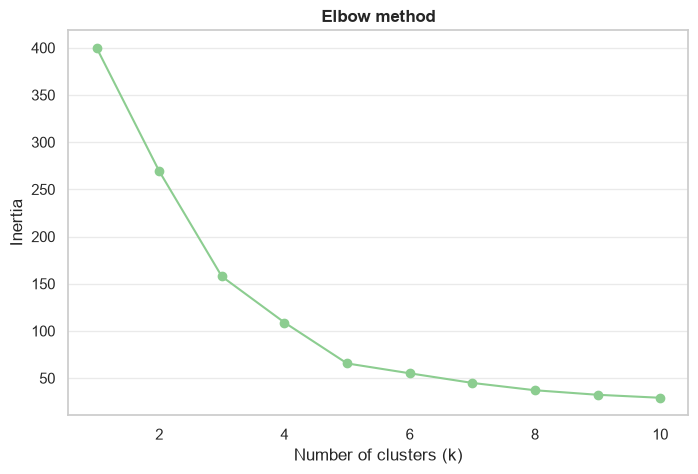

In [151]:
# inertia for k = 1..10
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    km.fit(shop_scaled)
    inertia.append(km.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow method')
plt.show()

The curve flattens after k = 5, so I choose 5 clusters.

#### 5. Perform Clustering using KMeans

In [152]:
kmeans = KMeans(n_clusters=5, random_state=0, n_init=10)
customer_data['kmeans_group'] = kmeans.fit_predict(shop_scaled)
customer_data['kmeans_group'].value_counts()

kmeans_group
0    81
1    39
2    35
3    23
4    22
Name: count, dtype: int64

#### 6. Plot scatter plot and color code in clustered groups

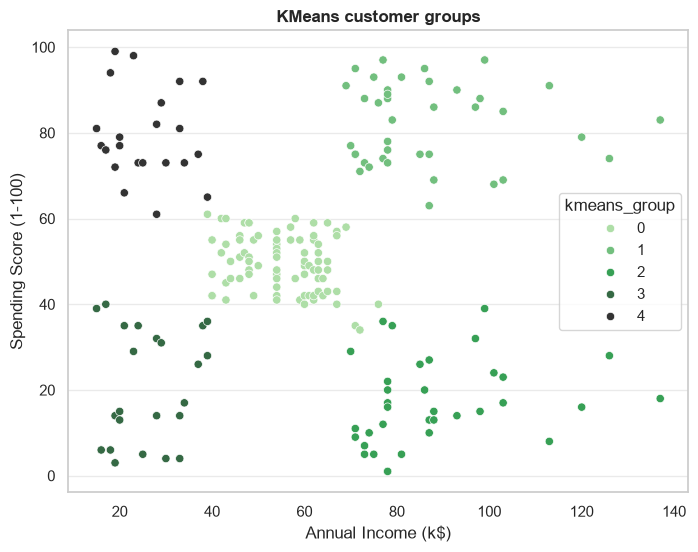

In [153]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=customer_data, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='kmeans_group', palette='Greens_d')
plt.title('KMeans customer groups')
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

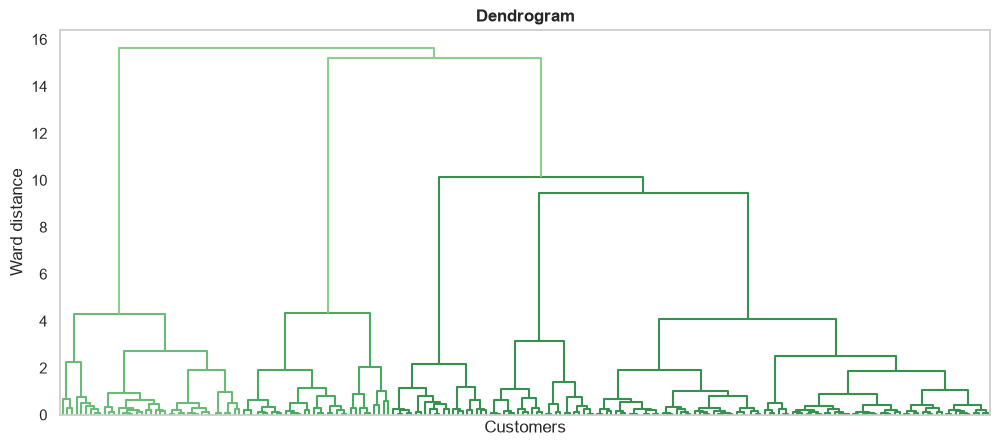

In [154]:
from scipy.cluster.hierarchy import dendrogram, linkage

plt.figure(figsize=(12, 5))
dendrogram(linkage(shop_scaled, method='ward'), no_labels=True)
plt.grid(False)
plt.xlabel('Customers')
plt.ylabel('Ward distance')
plt.title('Dendrogram')
plt.show()

Cutting at a distance of about 6 (in the long gap between ~4.5 and ~9.5) crosses 5 vertical lines. This matches the elbow method, so 5 clusters.

#### 8. Do clustering using Hierarchical Clustering

In [155]:
from sklearn.cluster import AgglomerativeClustering

hier = AgglomerativeClustering(n_clusters=5, linkage='ward')
customer_data['hier_group'] = hier.fit_predict(shop_scaled)

#### 9. Plot scatter plot and color code in clustered groups

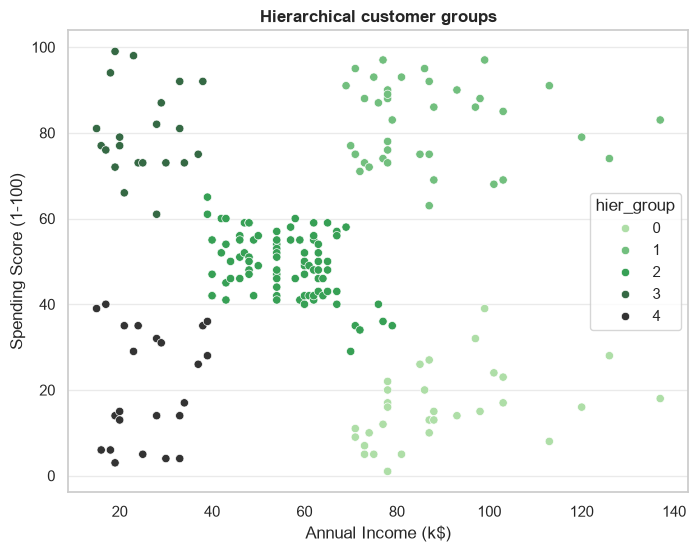

In [156]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=customer_data, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='hier_group', palette='Greens_d')
plt.title('Hierarchical customer groups')
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [157]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

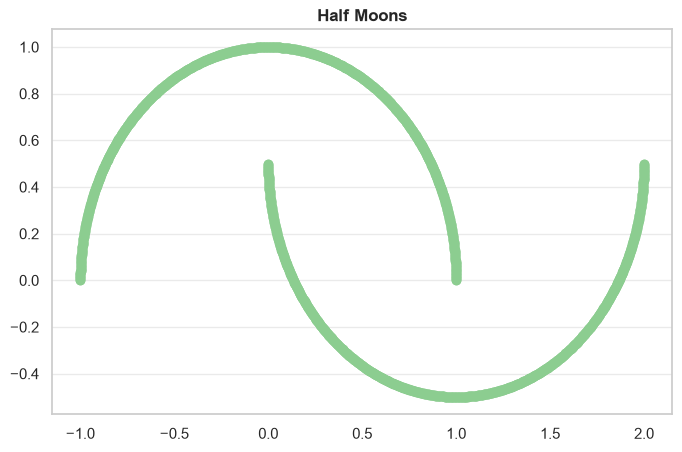

In [158]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [159]:
moon_km = KMeans(n_clusters=2, random_state=0, n_init=10)
moon_km_labels = moon_km.fit_predict(moons_X)

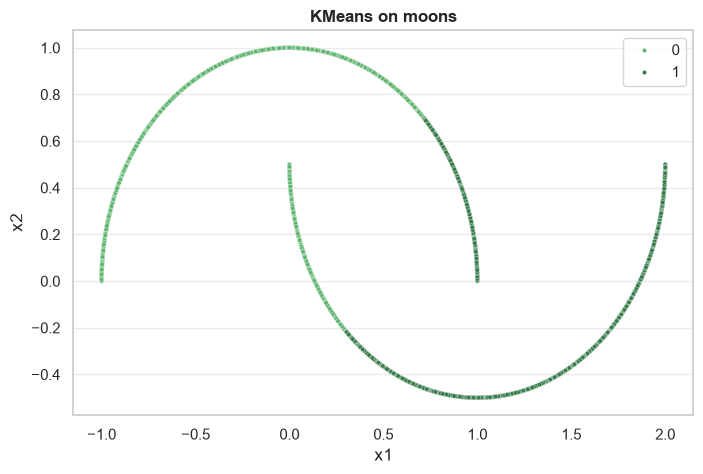

In [160]:
sns.scatterplot(x=moons_X[:, 0], y=moons_X[:, 1], hue=moon_km_labels, palette='Greens_d', s=10)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('KMeans on moons')
plt.show()

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

In [161]:
from sklearn.cluster import DBSCAN

# try a few eps values and see how many clusters / noise points we get
for eps in [0.05, 0.1, 0.2, 0.3]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(moons_X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f'eps={eps}: clusters={n_clusters}, noise={(labels == -1).sum()}')

eps=0.05: clusters=2, noise=0
eps=0.1: clusters=2, noise=0
eps=0.2: clusters=2, noise=0
eps=0.3: clusters=2, noise=0


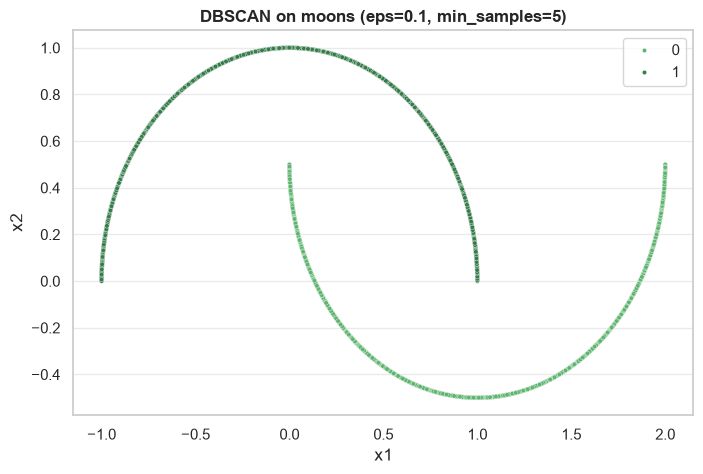

In [162]:
moon_db_labels = DBSCAN(eps=0.1, min_samples=5).fit_predict(moons_X)

sns.scatterplot(x=moons_X[:, 0], y=moons_X[:, 1], hue=moon_db_labels, palette='Greens_d', s=10)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('DBSCAN on moons (eps=0.1, min_samples=5)')
plt.show()

Every eps from 0.05 to 0.3 gives 2 clusters with no noise, so I chose eps=0.1, min_samples=5.

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

K-Means cuts each moon in half because it looks for round clusters. DBSCAN groups by density and finds both moons correctly, so it's better for this data.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [163]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [164]:
# decribe the data, its size
print('Shape:', penguins.shape)
penguins.info()
penguins.describe()

Shape: (344, 5)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


#### Based on dataframe describe, in own words explain any abnormal characteristics 

Flipper length has impossible values (max 5000, min -132), and some columns have missing values.

#### 14. Explore corrupted data

In [165]:
# find missing values. print entries with missing values, provide shape
print(penguins.isna().sum())
missing_rows = penguins[penguins.isna().any(axis=1)]
print('Shape:', missing_rows.shape)
missing_rows

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64
Shape: (9, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [166]:
# Examine sex column
penguins['sex'].value_counts(dropna=False)

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64

In [167]:
# find any unusual values. Print anomal rows
penguins[(penguins['flipper_length_mm'] < 100) | (penguins['flipper_length_mm'] > 300)]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE


9 rows have no sex, 1 has ".", and 2 have impossible flipper lengths (5000 and -132).

#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [168]:
# clean
num_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

peng_clean = penguins.dropna()
peng_clean = peng_clean[peng_clean['sex'].isin(['MALE', 'FEMALE'])]
peng_clean = peng_clean[peng_clean['flipper_length_mm'].between(100, 300)]

print('Shape:', peng_clean.shape)
peng_clean.head()

Shape: (332, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [169]:
# scale numerical columns. assign to a variable X_penguins
peng_scaler = StandardScaler()
X_penguins = peng_scaler.fit_transform(peng_clean[num_cols])

In [170]:
# assign categorical column to a variable y_penguins
y_penguins = peng_clean['sex']

#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

I dropped rows with missing values, invalid sex (".") or impossible flipper lengths. Pro: only real data is left, and just about 3% of rows are lost. Con: slightly less data.

#### 16. Perform PCA with 2 components. Plot the results 

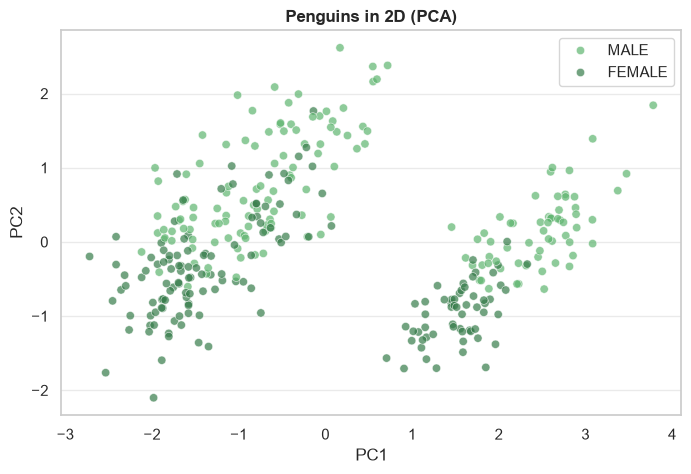

In [171]:
pca = PCA(n_components=2)
X_penguins_pca = pca.fit_transform(X_penguins)

sns.scatterplot(x=X_penguins_pca[:, 0], y=X_penguins_pca[:, 1], hue=y_penguins.values, palette='Greens_d', alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Penguins in 2D (PCA)')
plt.show()

The two big groups are most likely different species. Inside each group males sit higher (top-right) and females lower, with some overlap in the middle.

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

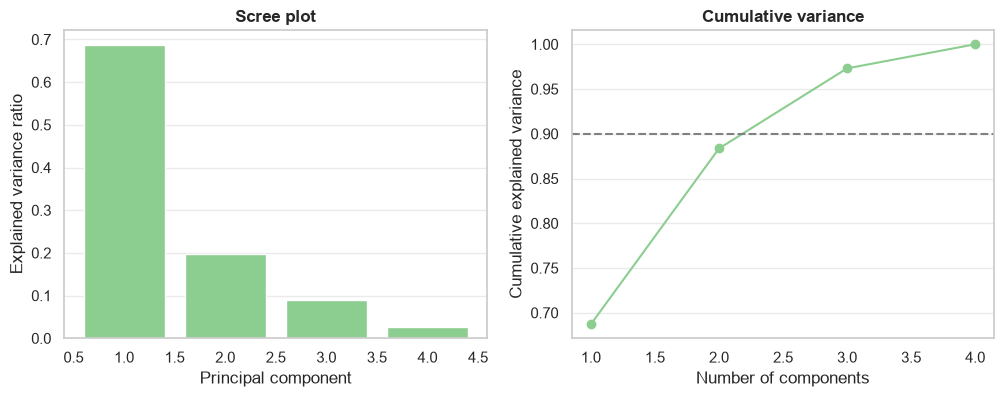

[0.687 0.196 0.09  0.027] [0.687 0.884 0.973 1.   ]


In [172]:
pca_all = PCA().fit(X_penguins)
ratio = pca_all.explained_variance_ratio_
pcs = range(1, len(ratio) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(pcs, ratio)
ax[0].set_xlabel('Principal component')
ax[0].set_ylabel('Explained variance ratio')
ax[0].set_title('Scree plot')

ax[1].plot(pcs, ratio.cumsum(), marker='o')
ax[1].axhline(0.9, linestyle='--', color='grey')
ax[1].set_xlabel('Number of components')
ax[1].set_ylabel('Cumulative explained variance')
ax[1].set_title('Cumulative variance')
plt.show()

print(ratio.round(3), ratio.cumsum().round(3))

PC1 + PC2 explain 88% of the variance and 3 PCs explain 97%. 2 PCs are enough for plotting; 3 pass the 90% line.

#### 18. Calculate (show in numbers) and display component loadings

In [173]:
# Component loadings (how much each original feature contributes to each PC)
loadings = pd.DataFrame(pca.components_.T, index=num_cols, columns=['PC1', 'PC2'])
loadings.round(3)

,PC1,PC2
culmen_length_mm,0.453,0.605
culmen_depth_mm,-0.399,0.793
flipper_length_mm,0.577,0.004
body_mass_g,0.550,0.072


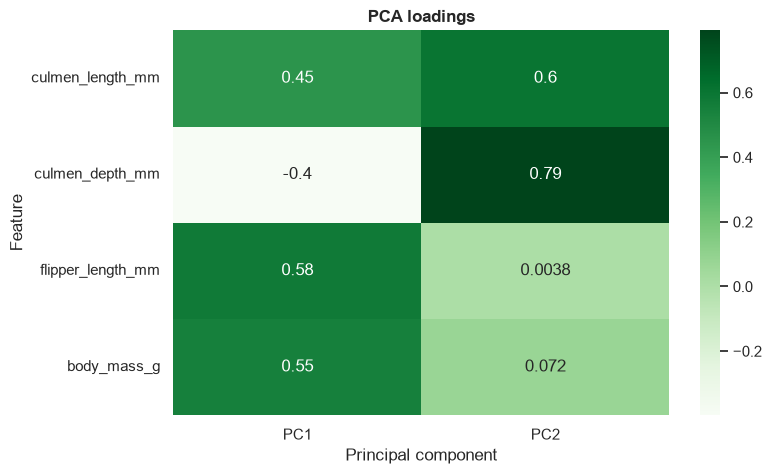

In [174]:
# show heatmap
sns.heatmap(loadings, annot=True, cmap='Greens')
plt.xlabel('Principal component')
plt.ylabel('Feature')
plt.title('PCA loadings')
plt.show()

PC1 ≈ body size (flipper and mass); PC2 is mostly culmen depth and length.

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [175]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_tr, X_te, y_tr, y_te = train_test_split(X_penguins_pca, y_penguins,
                                          test_size=0.25, random_state=0, stratify=y_penguins)

log_model = LogisticRegression()
log_model.fit(X_tr, y_tr)
pred = log_model.predict(X_te)

print('Accuracy:', round(accuracy_score(y_te, pred), 3))
print(confusion_matrix(y_te, pred))
print(classification_report(y_te, pred))

Accuracy: 0.795
[[33  8]
 [ 9 33]]
              precision    recall  f1-score   support

      FEMALE       0.79      0.80      0.80        41
        MALE       0.80      0.79      0.80        42

    accuracy                           0.80        83
   macro avg       0.80      0.80      0.80        83
weighted avg       0.80      0.80      0.80        83



Accuracy is about 80%. Errors are spread evenly between males and females. With only 2 PCs and 3 species mixed together, sex is hard to separate.

#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [176]:
# 1. take entries from original data with sex unknown, scale numerical columns
unknown = penguins[~penguins['sex'].isin(['MALE', 'FEMALE'])].dropna(subset=num_cols).copy()
X_unknown = peng_scaler.transform(unknown[num_cols])

In [177]:
# 2. apply the same PCA transformation to the new data
X_unknown_pca = pca.transform(X_unknown)

In [178]:
# 3. Train the model
# Define X_train and y_train using all PCA data from valid data
X_train = X_penguins_pca
y_train = y_penguins

# Train a classifier
final_model = LogisticRegression()
final_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [179]:
# 4. Make predictions on the new data. Display the features and predicted values
unknown['predicted_sex'] = final_model.predict(X_unknown_pca)
unknown

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,predicted_sex
8,34.1,18.1,193.0,3475.0,NaN,FEMALE
10,37.8,17.1,186.0,3300.0,NaN,FEMALE
11,37.8,17.3,180.0,3700.0,NaN,FEMALE
47,37.5,18.9,179.0,2975.0,NaN,FEMALE
246,44.5,14.3,216.0,4100.0,NaN,FEMALE
286,46.2,14.4,214.0,4650.0,NaN,FEMALE
324,47.3,13.8,216.0,4725.0,NaN,FEMALE
336,44.5,15.7,217.0,4875.0,.,FEMALE


All 8 unknown penguins were predicted FEMALE, probably because they're small.